**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: ---------Adolfo Siliceo Vásquez------------------------
*   MATRÍCULA: ---------01841467--------------------------

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [147]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

1. Descarga el archivo: `heart_disease.csv` y guarda, en un dataframe (`cardio_df`), todos sus registros.
* Haz que la columna `id` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.

In [148]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [149]:
#Descarga el archivo: heart_disease.csv y guarda, en un dataframe (cardio_df), todos sus registros.
cardio_df = pd.read_csv('/content/drive/MyDrive/Ciencia Analitica de Datos/Semana5/heart_disease.csv')

In [150]:
#Haz que la columna id sea el índice del dataframe.
cardio_df.set_index('id', inplace=True)


In [151]:
#Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
cardio_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


***hay 7 columnas numéricas y 8 de texto que pandas las indica como object***

In [152]:
#Determina la cantidad de valores únicos por columna.
cardio_df.nunique()

,0
age,50
sex,2
origin,4
cp,4
trestbps,60
chol,216
fbs,2
restecg,3
thalch,119
exang,2


2. Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.
* Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.

In [153]:
cardio_df['ca']  = pd.Categorical(cardio_df['ca'],  categories=[0, 1, 2, 3], ordered=True)
cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)

***LAs columnas ca y num son variables que presentaron pocos valores únicos, al ver su descripción observamos que son categoricas ordinales codificadas con números, así que con las dos instrucciones de arriba se procedió a convertirlas en categóricas estableciendo su orden.***

3. Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas.
* Para las numéricas, incluye el sesgo y la curtosis.
* Para las categóricas, imprime además las tablas de frecuencia.

In [154]:
#separamos las columnas en grupos
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
cat_cols = ['sex', 'origin', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal', 'num']

***NUMERICAS***

In [155]:
cardio_df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,918.0,53.530501,9.412783,28.0,47.0,54.0,60.0,77.0
trestbps,859.0,132.294529,18.535875,80.0,120.0,130.0,140.0,200.0
chol,888.0,242.189189,53.424806,85.0,216.0,223.0,268.0,603.0
thalch,863.0,137.528389,25.950226,60.0,120.0,140.0,157.0,202.0
oldpeak,856.0,0.880607,1.091840,-2.6,0.0,0.5,1.5,6.2


In [156]:
#sesgo
cardio_df[num_cols].skew()

,0
age,-0.193710
trestbps,0.630411
chol,1.640672
thalch,-0.209319
oldpeak,1.037990


In [157]:
#curtosis
cardio_df[num_cols].kurt()

,0
age,-0.382511
trestbps,0.632992
chol,6.573848
thalch,-0.483939
oldpeak,1.119834


***CATEGORICAS***

In [158]:
cardio_df[cat_cols].describe().T

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309,4,0,181
thal,434,3,normal,196
num,918,5,0,411


In [159]:
#tablas de frecuencia
for columnas in cat_cols:
    print(cardio_df[columnas].value_counts())
    print('********************')

sex
Male      724
Female    194
Name: count, dtype: int64
********************
origin
Cleveland        304
Hungary          292
VA Long Beach    200
Switzerland      122
Name: count, dtype: int64
********************
cp
asymptomatic       495
non-anginal        204
atypical angina    174
typical angina      45
Name: count, dtype: int64
********************
fbs
False    691
True     138
Name: count, dtype: int64
********************
restecg
normal              551
lv hypertrophy      188
st-t abnormality    179
Name: count, dtype: int64
********************
exang
False    526
True     337
Name: count, dtype: int64
********************
slope
flat           345
upsloping      202
downsloping     63
Name: count, dtype: int64
********************
ca
0    181
1     67
2     41
3     20
Name: count, dtype: int64
********************
thal
normal               196
reversable defect    192
fixed defect          46
Name: count, dtype: int64
********************
num
0    411
1    263
2    109
3   

4. Calcula el porcentaje de valores faltantes en cada columna.
* Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
* Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
* Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.

In [160]:
#Calcula el porcentaje de valores faltantes en cada columna.
(cardio_df.isna().sum() / cardio_df.shape[0] * 100).round(2).sort_values(ascending=False)

,0
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
thalch,5.99
exang,5.99
chol,3.27
sex,0.00


In [161]:
#Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.
cardio_df = cardio_df.drop(columns=['ca', 'thal', 'slope'])

***vemos que las columnas a eliminar son 'ca', 'thal' y 'slope' ya que superan el 30% de valores faltantes***

Text(0.5, 1.0, 'mapa de calor de Distribución de valores faltantes')

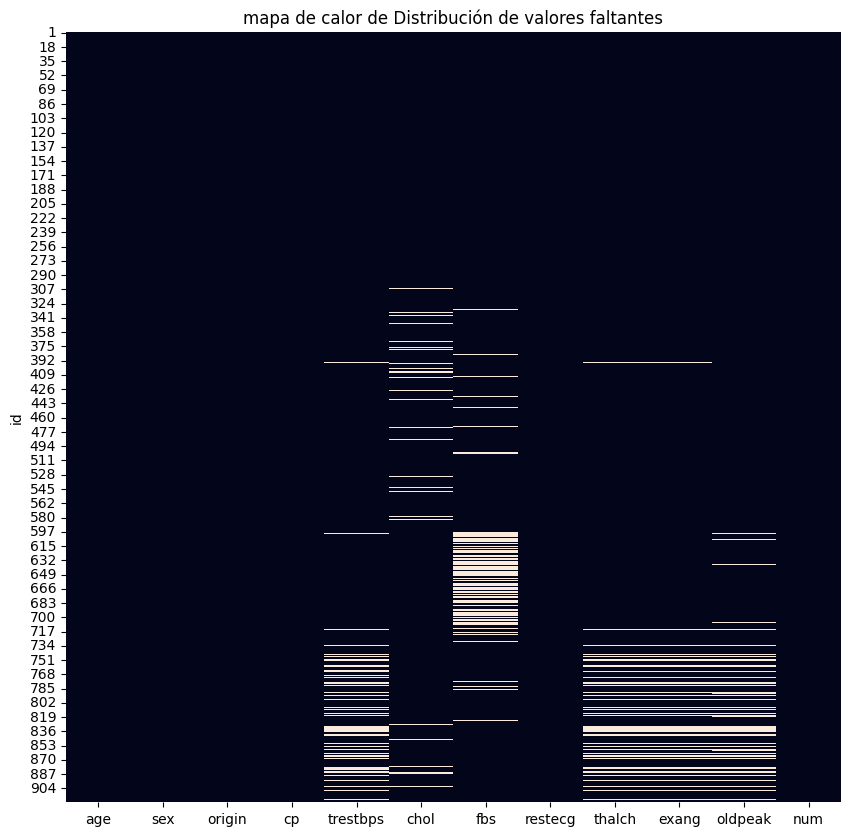

In [162]:
#Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.
plt.figure(figsize=(10,10))
sns.heatmap(cardio_df.isna(), cbar=False)
plt.title('mapa de calor de Distribución de valores faltantes')

In [163]:
#Algunas variables presentan valores faltantes de manera simultánea; es decir,
#en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo.
#Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.
na = cardio_df.isna()
na.astype(int).corr().round(2)

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
age,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cp,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
trestbps,NaN,NaN,NaN,NaN,1.00,0.03,-0.07,NaN,0.96,0.96,0.90,NaN
chol,NaN,NaN,NaN,NaN,0.03,1.00,-0.06,NaN,0.03,0.03,0.02,NaN
fbs,NaN,NaN,NaN,NaN,-0.07,-0.06,1.00,NaN,-0.08,-0.08,-0.03,NaN
restecg,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
thalch,NaN,NaN,NaN,NaN,0.96,0.03,-0.08,NaN,1.00,1.00,0.92,NaN
exang,NaN,NaN,NaN,NaN,0.96,0.03,-0.08,NaN,1.00,1.00,0.92,NaN


***las variables que tienen filas con valores faltantes de forma simultánea son trestbps, thalch, exang y oldpeak***
***Estás tres columnas están relacionadas ya que son mediciones que provienen del mismo estudio clínico llamado "Ergometría o Prueba de Esfuerzo Cardíaco". la mayoría de estos registros con valores faltantes tuvieron origen en "VA Long Beach" y en la columna "age" vemos que fueron pacientes de edad avanzada, por lo que se podría deducir que estos pacientes no pueden realizar una prueba de esfuerzo cardiaco debido a su edad.***
***Por otro lado, revizando los antecedentes, Long Beach tuvo una población conformada en su mayoría por veteranos en la epoca de los 80's, misma época en la que se creo el muestreo de datos Heart Disease.csv***

5. Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.

* ¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable? Analízalo considerando las siguientes columnas:
  *   Numéricas: `age`, `chol`
  *   Categóricas: `restecg`, `cp`

Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.
* Incluye las conclusiones del análisis con los resultados obtenidos.
* Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).

**NOTA**. Puedes reutilizar las funciones `Diagnose_MV_Numerical` y `Diagnose_MV_Categorical` definidas en Hands-On-Prep_Missing_Values.zip. Revisa nuevamente cómo utilizarlas.

In [164]:
from scipy.stats import ttest_ind
def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [165]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

Diagnosis Analysis for age:


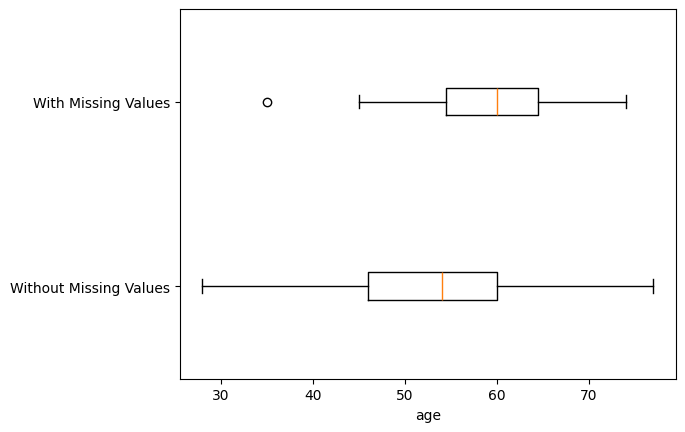

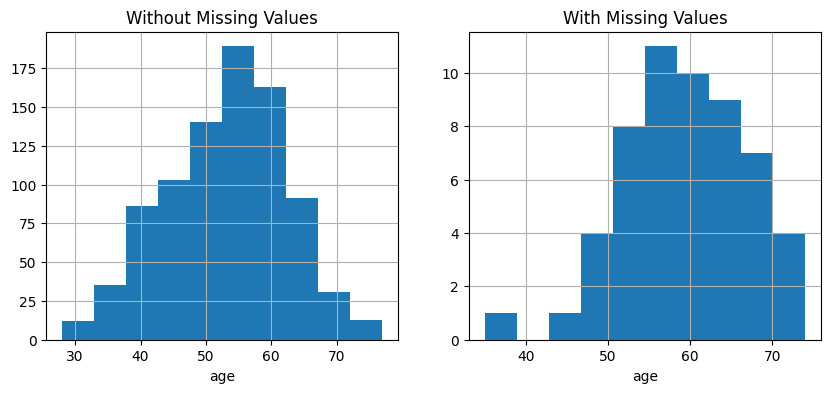

p-value of t-test: 1.5041244185890902e-06
- - - - - - - - - - divider - - - - - - - - - 
Diagnosis Analysis for chol:


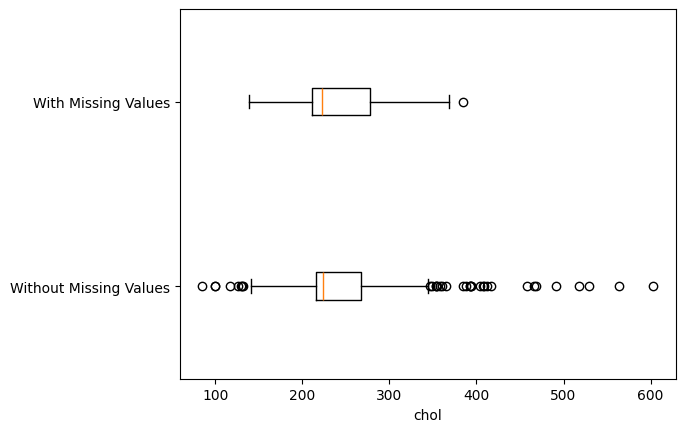

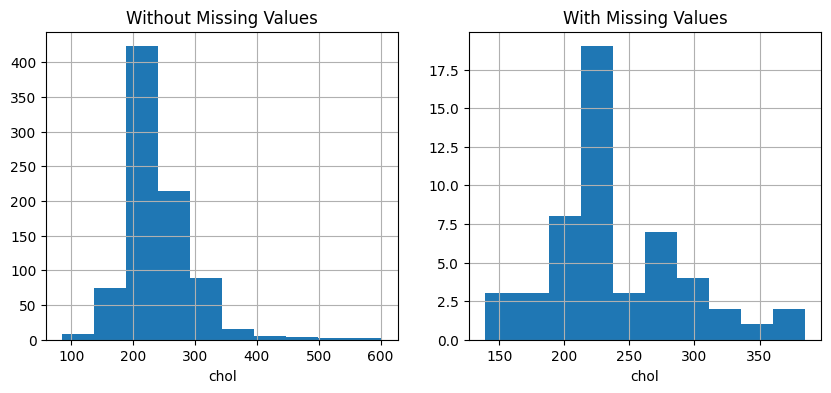

p-value of t-test: 0.7165289974295672
- - - - - - - - - - divider - - - - - - - - - 
Diagnosis Analysis for restecg:


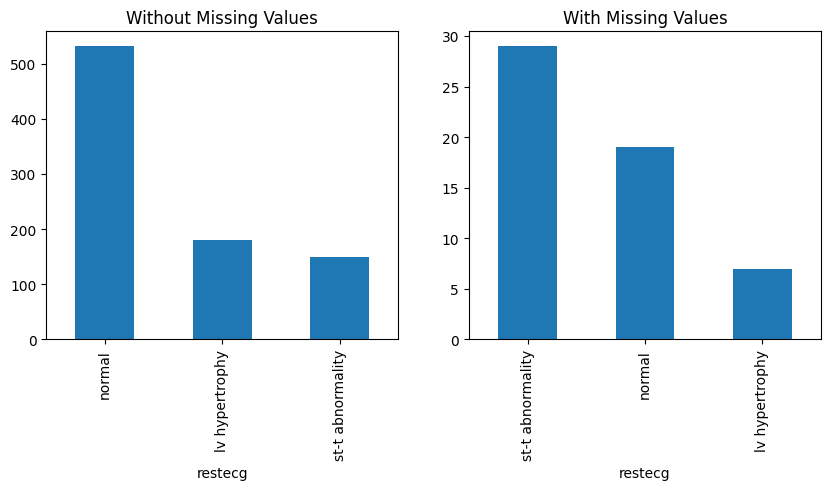

p-value of Chi_squared test: 1.1472889573985467e-09
- - - - - - - - - - divider - - - - - - - - - 
Diagnosis Analysis for cp:


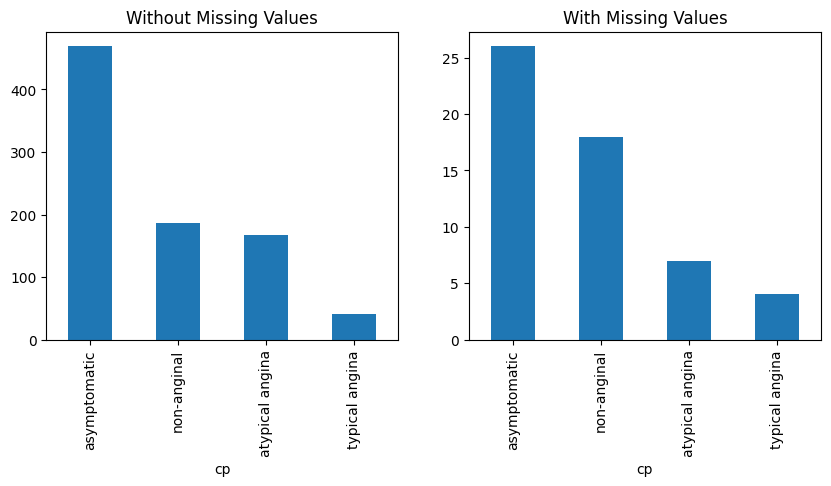

p-value of Chi_squared test: 0.15420097177251701
- - - - - - - - - - divider - - - - - - - - - 


In [166]:
BM_MV = cardio_df.thalch.isna()

numerical_attributes = ['age', 'chol']
categorical_attributes = ['restecg', 'cp']

for att in numerical_attributes:
    print('Diagnosis Analysis for {}:'.format(att))
    Diagnose_MV_Numerical(cardio_df, att, BM_MV)
    print('- - - - - - - - - - divider - - - - - - - - - ')

for att in categorical_attributes:
    print('Diagnosis Analysis for {}:'.format(att))
    Diagnose_MV_Categorical(cardio_df, att, BM_MV)
    print('- - - - - - - - - - divider - - - - - - - - - ')

de acuerdo con los boxplots e histogramas de los atributos numericos:

***age***:- el boxplot de valores faltantes está mas cargado hacia las edades mayores, vemos que el paciente más joven del rango intercuartílico es más viejo que el paciente promedio del "grupo sin faltante" por lo que podemos decir que los pacientes a los que les falta el valor en thalch son mayores.
en los boxplot vemos que hay una diferencia entre las dos poblaciones, por lo cual, la edad si pudo haber influido en los valores faltantes en thalch.
en cuanto al p_value de age es 0.0000015041244185890902 el cual está por debajo del 0.05, por lo que para age si hay relación y rechazamos la hipótesis nula.

***chol***:- el boxplot de ambas poblaciones muestran que no hay una diferencia significativa en la posicion de la caja. por lo que vemos que el colesterol no tse encontró evidencia significativa de que haya influido en los faltantes de thalch.
en cuanto al p-value de chol, este es de 0.7165289974295672 el cual es mayor del 0.05, lo que nos dice que no hay evidencia de la relación, no hay diferencia  significativa, así que no se rechaza la hipotesis nula.

***restecg***:- vemos en la gráfica de barras que la variable categórica normal es la que predomina en la población "sin faltantes" y la que menos predomina es  la categorica st-abnormality, pero en la población "con faltantes" se invierten, predomina st-abnormality y  la categórica normal cae, por lo que hay una diferencia significativa.
en cuanto al p-value, este es de 0.0000000011472889573985467 el cual está por debajo de 0.05 lo que indica que si hay diferencia significativa y rechazamos la hipótesis nula

***cp***: vemos que en ambas gráficas el perfil de cada categórica se conserva en cuanto a sus proporciones por lo que no hay una diferencia significativa, la categórica que predomina en una población, predomina en la otra, por el contrario, la que menos predomina en una población de igual forma es la que menos predomina en la otra.
en cuanto a su p-value, este es de valor 0.15420097177251701 el cual es mayor  del 0.05 , así que no se rechaza la hipotesis nula.

***el mecanismo de faltantes es MAR, en las lecturas de la semana5 en el ejercicio NO2_Location_A se deja en claro que ahí, el mecanismo de faltantes era MCAR ya que se necesita que ninguna variable observada del conjunto de datos tenga relación con la aparición de los faltantes. Este no es nuestro caso ya que aquí dos variables si tienen relacion con los faltantes en thalch (age y restecg) y dos que no a tienen (cp y chol), por lo que se descarta que sea MCAR***

6. La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`

* Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4) Asegúrate de cambiar la función de agregado si hay variables no numéricas.
* Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.

In [167]:
cardio_df['exang'] = pd.Categorical(cardio_df['exang'])

# mediana por grupo
for col in ['thalch', 'trestbps', 'oldpeak']:
    cardio_df[col] = cardio_df.groupby('restecg')[col].transform(lambda x: x.fillna(x.median()))

# moda por grupo
cardio_df['exang'] = cardio_df.groupby('restecg')['exang'].transform(lambda x: x.fillna(x.mode()[0]))

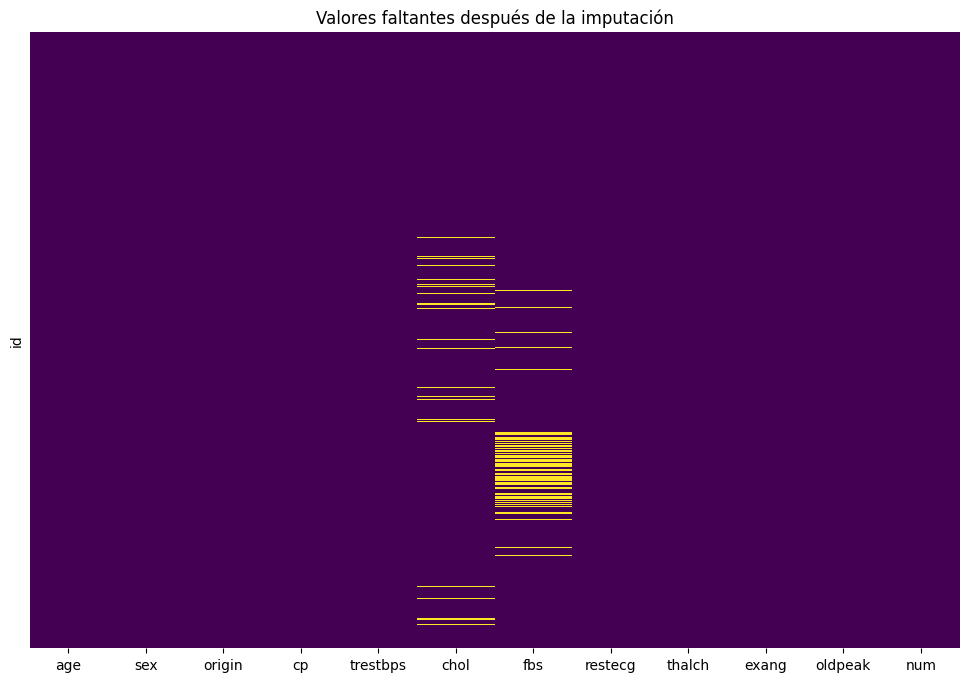

In [168]:
#Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.
plt.figure(figsize=(12, 8))
sns.heatmap(cardio_df.isna(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Valores faltantes después de la imputación')
plt.show()

7. Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn
* Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.


In [169]:
from sklearn.impute import SimpleImputer

# chol --> median
imp_numero = SimpleImputer(strategy='median')
cardio_df[['chol']] = imp_numero.fit_transform(cardio_df[['chol']])

# fbs --> most_frequent
imp_categ = SimpleImputer(strategy='most_frequent')
cardio_df[['fbs']] = imp_categ.fit_transform(cardio_df[['fbs']])

###Justifica la estrategia (mean, median, most_frequent) que emplees en cada caso.
***para la imputación  de los valores faltantes de chol se eligió la mediana, debido a que en vimos en los boxplot anteriores que chol presenta valores atípicos notables. chol presentó sesgo positico alto. chol tuvo un valor máximo de 603 mg/dl contra una media de 2.42.19.
en la bibliografía recomndada para la semana5 se menciona que cuando una variable  prsenta una asimetría pronunciada o valores atípicos altos, la mediana es una medida robusta que no se deja modificar o influenciar por los valores extremos.***

***para justificación de usar la  moda para la variable fbs, esta es una categórica que solo tiene valores TRUE y FALSE.
en la biliografía recomendada se menciona que para rellenar atributos que son de tipo categóricos de acuerdo con su frecuncia es preferible usar la moda. en este caso el valor más comun es FALSE el cual representa el 83% de los registros que observamos.***

8. Dibuja boxplots de todas las variables numéricas.
* Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.

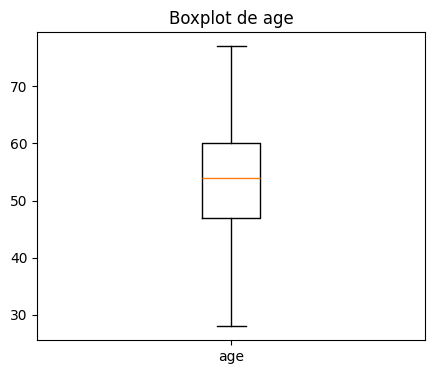

age: 0 valores atípicos
[]
------------------------------------------------------


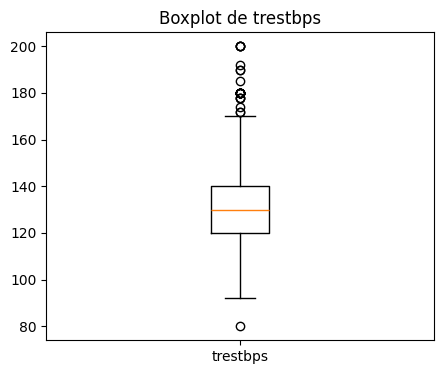

trestbps: 27 valores atípicos
[np.float64(80.0), np.float64(172.0), np.float64(172.0), np.float64(174.0), np.float64(178.0), np.float64(178.0), np.float64(178.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(180.0), np.float64(185.0), np.float64(190.0), np.float64(190.0), np.float64(192.0), np.float64(200.0), np.float64(200.0), np.float64(200.0), np.float64(200.0)]
------------------------------------------------------


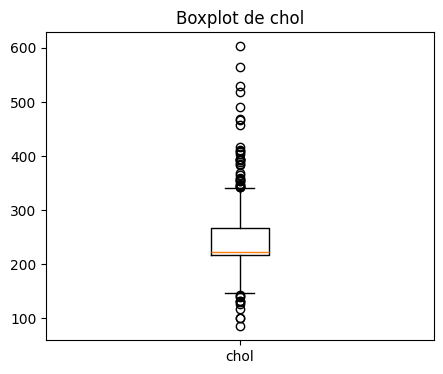

chol: 44 valores atípicos
[np.float64(85.0), np.float64(100.0), np.float64(100.0), np.float64(117.0), np.float64(126.0), np.float64(129.0), np.float64(131.0), np.float64(132.0), np.float64(139.0), np.float64(141.0), np.float64(142.0), np.float64(342.0), np.float64(342.0), np.float64(342.0), np.float64(344.0), np.float64(347.0), np.float64(349.0), np.float64(353.0), np.float64(354.0), np.float64(355.0), np.float64(358.0), np.float64(360.0), np.float64(365.0), np.float64(369.0), np.float64(384.0), np.float64(385.0), np.float64(388.0), np.float64(392.0), np.float64(393.0), np.float64(394.0), np.float64(394.0), np.float64(404.0), np.float64(407.0), np.float64(409.0), np.float64(412.0), np.float64(417.0), np.float64(458.0), np.float64(466.0), np.float64(468.0), np.float64(491.0), np.float64(518.0), np.float64(529.0), np.float64(564.0), np.float64(603.0)]
------------------------------------------------------


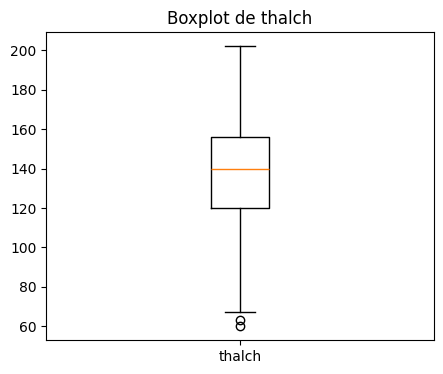

thalch: 2 valores atípicos
[np.float64(60.0), np.float64(63.0)]
------------------------------------------------------


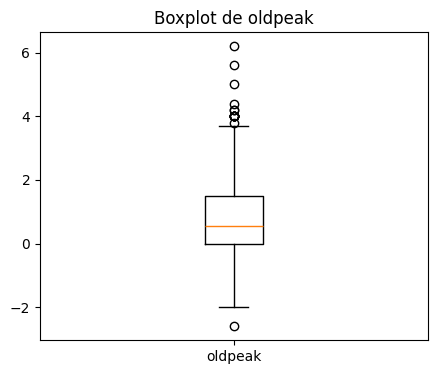

oldpeak: 16 valores atípicos
[np.float64(-2.6), np.float64(3.8), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.0), np.float64(4.2), np.float64(4.2), np.float64(4.4), np.float64(5.0), np.float64(5.6), np.float64(6.2)]
------------------------------------------------------


In [170]:
columnas_num = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

##boxplots
for col in columnas_num:
    plt.figure(figsize=(5, 4))
    fig = plt.boxplot(cardio_df[col], tick_labels=[col])
    plt.title('Boxplot de ' + col)
    plt.show()
#Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot
    atipicos = fig['fliers'][0].get_data()[1]
    print(f'{col}: {len(atipicos)} valores atípicos')
    print(sorted(atipicos))
    print('------------------------------------------------------')



**los valores atípicos  que dieron como resultado de los boxplots serían los siguientes:**

**age: 0 valores atípicos**

**trestbps: 27 valores atípicos**

**chol: 44 valores atípicos**

**thalch: 2 valores atípicos**

**oldpeak: 16 valores atípicos**




9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).
* Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.
* Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.

In [171]:
Q1 = cardio_df.trestbps.quantile(0.25)
Q3 = cardio_df.trestbps.quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print('primer cuartil Q1 =', Q1)
print('tercer cuartil Q3 =', Q3)
print('rango intercuartílico IQR =', IQR)
print('Límites inferior y superior : [', limite_inferior, ',', limite_superior, ']')

BM = (cardio_df.trestbps > (Q3 + 1.5 * IQR)) | (cardio_df.trestbps < (Q1 - 1.5 * IQR))
cardio_df[BM].sort_values('trestbps' , ascending=False)

primer cuartil Q1 = 120.0
tercer cuartil Q3 = 140.0
rango intercuartílico IQR = 20.0
Límites inferior y superior : [ 90.0 , 170.0 ]


,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
id,,,,,,,,,,,,
127,56,Female,Cleveland,asymptomatic,200.0,288.0,True,lv hypertrophy,133.0,True,4.0,3
681,61,Male,Switzerland,non-anginal,200.0,223.0,False,st-t abnormality,70.0,False,0.0,3
549,54,Male,Hungary,asymptomatic,200.0,198.0,False,normal,142.0,True,2.0,1
702,64,Female,Switzerland,asymptomatic,200.0,223.0,False,normal,140.0,True,1.0,3
189,54,Male,Cleveland,atypical angina,192.0,283.0,False,lv hypertrophy,195.0,False,0.0,1
897,61,Male,VA Long Beach,asymptomatic,190.0,287.0,True,lv hypertrophy,150.0,True,2.0,4
339,39,Male,Hungary,atypical angina,190.0,241.0,False,normal,106.0,False,0.0,0
701,63,Male,Switzerland,asymptomatic,185.0,223.0,False,normal,98.0,True,0.0,1
376,45,Female,Hungary,atypical angina,180.0,223.0,False,normal,180.0,False,0.0,0


**al mostrar BM, vemos que tenemos 27 valores atípicos, vemos el valor 80 que estaría por debajo del limite inferior de 90 y por encima de 170 vemos 27 registros atípicos, estos van del 172.0 al 200.0 dando un total de 27 registros atípicos.**

**revisando el ejercicio anterior de los boxplots vemos que concuerda con los 27 valores atípicos que encontramos**

10. Elimina los valores atípicos identificados de la variable `trestbps`.
* Dibuja el boxplot final para visualizar la distribución depurada.

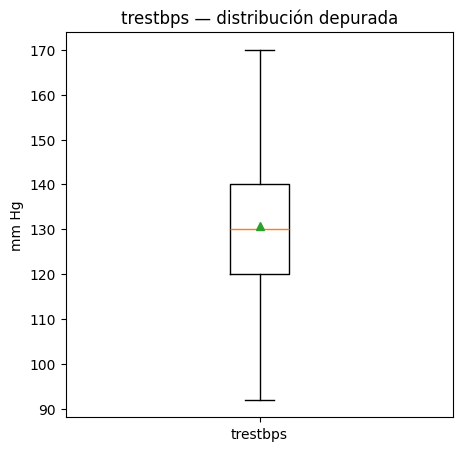

In [172]:
BM = (cardio_df.trestbps > limite_superior) | (cardio_df.trestbps < limite_inferior)

cardio_df = cardio_df[~BM]


#Dibuja el boxplot final para visualizar la distribución depurada.
plt.figure(figsize=(5, 5))
plt.boxplot(cardio_df.trestbps, tick_labels=['trestbps'], showmeans=True)
plt.title('trestbps — distribución depurada')
plt.ylabel('mm Hg')
plt.show()

Anthropic. (2026). Claude (Opus 5.5) [Modelo de lenguaje grande], utilizado como tutor personal en cuanto a resolución de dudas. https://claude.ai/

---

**Declaración de uso de IA**

Si aplica, deberá indicarse la herramienta y el modelo empleado en la entrega, así como la finalidad de su uso (generación de código / depuración / optimización).

Por ejemplo:

*   OpenAI. (2026). *ChatGPT (basado en GPT-4)* [Modelo de lenguaje grande], utilizado para generación de código y depuración. https://chat.openai.com/

---